# **Week 10 – House Price Visualization, Spatial Analytics & Real-Estate Insights**

1.Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import os
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

2. Upload and load the cleaned dataset

In [2]:
df = pd.read_csv("/content/drive/MyDrive/EDA-Skill/house_sales_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (21613, 34)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sale_day,property_age,is_renovated,renovation_year,years_since_renovation,price_per_sqft_living,price_per_sqft_lot,total_rooms,living_lot_ratio,property_age_category
0,7129300520,2014-10-13,221900.0,3.0,1.00,1180.0,5650.0,1.0,0,0,...,13,59,0,NaN,NaN,188.050847,39.274336,4.00,0.208850,Old
1,6414100192,2014-12-09,538000.0,3.0,2.25,2570.0,7242.0,2.0,0,0,...,9,63,1,1991.0,23.0,209.338521,74.288870,5.25,0.354874,Old
2,5631500400,2015-02-25,180000.0,2.0,1.00,770.0,10000.0,1.0,0,0,...,25,82,0,NaN,NaN,233.766234,18.000000,3.00,0.077000,Old
3,2487200875,2014-12-09,604000.0,4.0,3.00,1960.0,5000.0,1.0,0,0,...,9,49,0,NaN,NaN,308.163265,120.800000,7.00,0.392000,Middle Aged
4,1954400510,2015-02-18,510000.0,3.0,2.00,1680.0,8080.0,1.0,0,0,...,18,28,0,NaN,NaN,303.571429,63.118812,5.00,0.207921,Middle Aged


3. Understand the dataset

In [3]:
print("Dataset Information")
print(df.info())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
display(df.isnull().sum())

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      21613 non-null  int64  
 1   date                    21613 non-null  object 
 2   price                   21613 non-null  float64
 3   bedrooms                21600 non-null  float64
 4   bathrooms               21603 non-null  float64
 5   sqft_living             21613 non-null  float64
 6   sqft_lot                21613 non-null  float64
 7   floors                  21613 non-null  float64
 8   waterfront              21613 non-null  int64  
 9   view                    21613 non-null  int64  
 10  condition               21613 non-null  int64  
 11  grade                   21613 non-null  int64  
 12  sqft_above              21613 non-null  int64  
 13  sqft_basement           21613 non-null  int64  
 14  yr_built          

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sale_quarter,sale_day,property_age,is_renovated,renovation_year,years_since_renovation,price_per_sqft_living,price_per_sqft_lot,total_rooms,living_lot_ratio
count,2.161300e+04,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,...,21613.000000,21613.000000,21613.000000,21613.000000,914.000000,914.000000,21613.000000,21613.000000,21597.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,...,2.524777,15.688197,43.317818,0.042289,1995.827133,18.443107,264.156594,88.966710,5.489026,0.323745
std,2.876566e+09,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,...,1.034210,8.635063,29.375493,0.201253,15.517107,15.528920,110.060793,94.055247,1.477276,0.268565
min,1.000102e+06,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,...,1.000000,1.000000,-1.000000,0.000000,1934.000000,-1.000000,87.588235,0.163119,1.500000,0.000610
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,...,2.000000,8.000000,18.000000,0.000000,1987.000000,7.000000,182.291667,33.333333,4.500000,0.156581
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,...,2.000000,16.000000,40.000000,0.000000,2000.000000,15.000000,244.644550,59.223301,5.500000,0.247664
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,...,3.000000,23.000000,63.000000,0.000000,2007.000000,27.000000,318.322981,107.594937,6.500000,0.407547
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,...,4.000000,31.000000,115.000000,1.000000,2015.000000,80.000000,810.138889,2027.208539,34.750000,4.653846



Missing Values:


,0
id,0
date,0
price,0
bedrooms,13
bathrooms,10
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


In [4]:
required_columns = [
    "price",
    "sqft_living",
    "grade",
    "waterfront",
    "lat",
    "long"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

print("All required columns are available.")

All required columns are available.


4. Prepare data for visualization

In [5]:
# Convert required columns into numeric format
numeric_columns = [
    "price",
    "sqft_living",
    "grade",
    "waterfront",
    "lat",
    "long"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove records with missing values in essential fields
df = df.dropna(subset=required_columns).copy()

# Remove invalid price and living area values
df = df[
    (df["price"] > 0) &
    (df["sqft_living"] > 0)
].copy()

# Create price per square foot
df["price_per_sqft"] = (
    df["price"] / df["sqft_living"]
)

# Create waterfront labels
df["waterfront_label"] = df["waterfront"].map({
    0: "Non-Waterfront",
    1: "Waterfront"
})

print("Prepared dataset shape:", df.shape)

display(df.head())

Prepared dataset shape: (21613, 36)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,is_renovated,renovation_year,years_since_renovation,price_per_sqft_living,price_per_sqft_lot,total_rooms,living_lot_ratio,property_age_category,price_per_sqft,waterfront_label
0,7129300520,2014-10-13,221900.0,3.0,1.00,1180.0,5650.0,1.0,0,0,...,0,NaN,NaN,188.050847,39.274336,4.00,0.208850,Old,188.050847,Non-Waterfront
1,6414100192,2014-12-09,538000.0,3.0,2.25,2570.0,7242.0,2.0,0,0,...,1,1991.0,23.0,209.338521,74.288870,5.25,0.354874,Old,209.338521,Non-Waterfront
2,5631500400,2015-02-25,180000.0,2.0,1.00,770.0,10000.0,1.0,0,0,...,0,NaN,NaN,233.766234,18.000000,3.00,0.077000,Old,233.766234,Non-Waterfront
3,2487200875,2014-12-09,604000.0,4.0,3.00,1960.0,5000.0,1.0,0,0,...,0,NaN,NaN,308.163265,120.800000,7.00,0.392000,Middle Aged,308.163265,Non-Waterfront
4,1954400510,2015-02-18,510000.0,3.0,2.00,1680.0,8080.0,1.0,0,0,...,0,NaN,NaN,303.571429,63.118812,5.00,0.207921,Middle Aged,303.571429,Non-Waterfront


4. Prepare data for visualization

In [6]:
# Convert required columns into numeric format
numeric_columns = [
    "price",
    "sqft_living",
    "grade",
    "waterfront",
    "lat",
    "long"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove records with missing values in essential fields
df = df.dropna(subset=required_columns).copy()

# Remove invalid price and living area values
df = df[
    (df["price"] > 0) &
    (df["sqft_living"] > 0)
].copy()

# Create price per square foot
df["price_per_sqft"] = (
    df["price"] / df["sqft_living"]
)

# Create waterfront labels
df["waterfront_label"] = df["waterfront"].map({
    0: "Non-Waterfront",
    1: "Waterfront"
})

print("Prepared dataset shape:", df.shape)

display(df.head())

Prepared dataset shape: (21613, 36)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,is_renovated,renovation_year,years_since_renovation,price_per_sqft_living,price_per_sqft_lot,total_rooms,living_lot_ratio,property_age_category,price_per_sqft,waterfront_label
0,7129300520,2014-10-13,221900.0,3.0,1.00,1180.0,5650.0,1.0,0,0,...,0,NaN,NaN,188.050847,39.274336,4.00,0.208850,Old,188.050847,Non-Waterfront
1,6414100192,2014-12-09,538000.0,3.0,2.25,2570.0,7242.0,2.0,0,0,...,1,1991.0,23.0,209.338521,74.288870,5.25,0.354874,Old,209.338521,Non-Waterfront
2,5631500400,2015-02-25,180000.0,2.0,1.00,770.0,10000.0,1.0,0,0,...,0,NaN,NaN,233.766234,18.000000,3.00,0.077000,Old,233.766234,Non-Waterfront
3,2487200875,2014-12-09,604000.0,4.0,3.00,1960.0,5000.0,1.0,0,0,...,0,NaN,NaN,308.163265,120.800000,7.00,0.392000,Middle Aged,308.163265,Non-Waterfront
4,1954400510,2015-02-18,510000.0,3.0,2.00,1680.0,8080.0,1.0,0,0,...,0,NaN,NaN,303.571429,63.118812,5.00,0.207921,Middle Aged,303.571429,Non-Waterfront


5. Living area vs house price

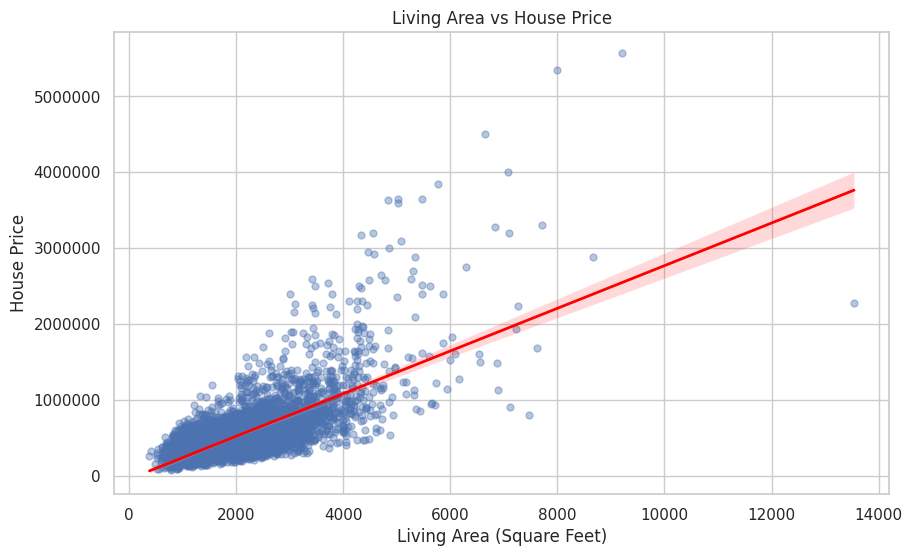

In [7]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df.sample(
        min(5000, len(df)),
        random_state=42
    ),
    x="sqft_living",
    y="price",
    scatter_kws={
        "alpha": 0.4,
        "s": 25
    },
    line_kws={
        "color": "red",
        "linewidth": 2
    }
)

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("House Price")
plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.show()

In [8]:
living_price_correlation = df[
    ["sqft_living", "price"]
].corr()

display(living_price_correlation)

print(
    "Correlation between living area and price:",
    round(
        df["sqft_living"].corr(df["price"]),
        3
    )
)

,sqft_living,price
sqft_living,1.000000,0.702035
price,0.702035,1.000000


Correlation between living area and price: 0.702


6. House price comparison across property grades

In [9]:
grade_summary = (
    df.groupby("grade")["price"]
    .agg(
        ["count", "mean", "median", "min", "max"]
    )
    .round(2)
    .reset_index()
)

display(grade_summary)

,grade,count,mean,median,min,max
0,1,1,142000.00,142000.0,142000.0,142000.0
1,3,3,205666.67,262000.0,75000.0,280000.0
2,4,29,214381.03,205000.0,80000.0,435000.0
3,5,242,248523.97,228700.0,78000.0,795000.0
4,6,2038,301919.64,275276.5,82000.0,1200000.0
5,7,8981,402590.26,375000.0,90000.0,2050000.0
6,8,6068,542852.77,510000.0,140000.0,3070000.0
7,9,2615,773513.19,720000.0,230000.0,2700000.0
8,10,1134,1071771.07,914327.0,316000.0,3600000.0
9,11,399,1496841.73,1284000.0,420000.0,7062500.0


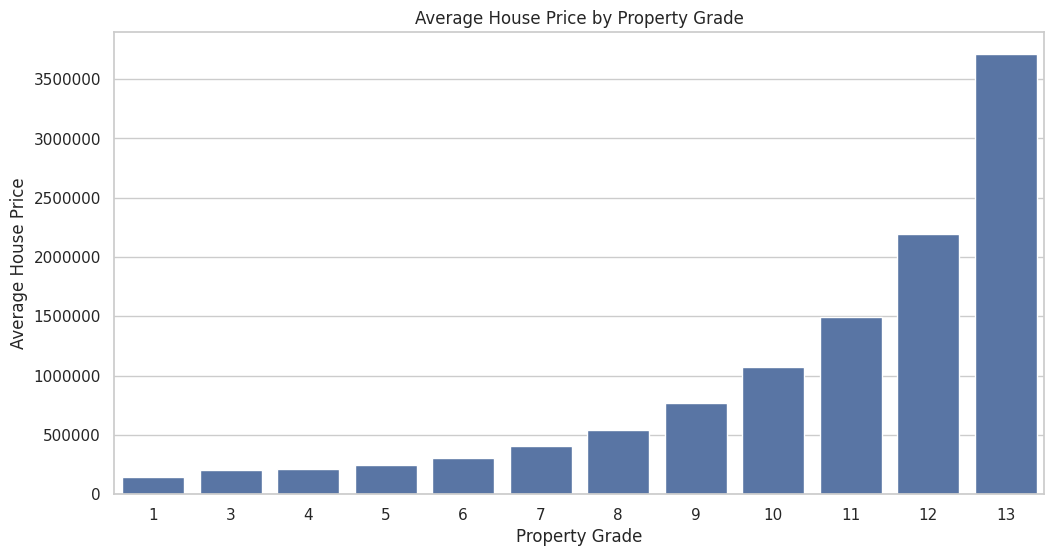

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=grade_summary,
    x="grade",
    y="mean"
)

plt.title("Average House Price by Property Grade")
plt.xlabel("Property Grade")
plt.ylabel("Average House Price")
plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.show()

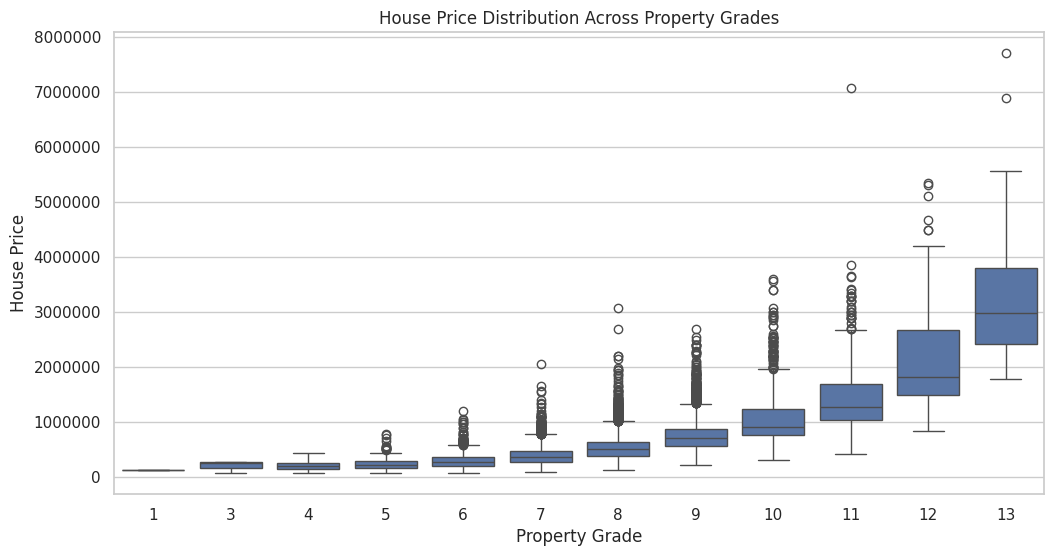

In [11]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="grade",
    y="price"
)

plt.title("House Price Distribution Across Property Grades")
plt.xlabel("Property Grade")
plt.ylabel("House Price")
plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.show()

7. Waterfront vs non-waterfront property analysis

In [12]:
waterfront_summary = (
    df.groupby("waterfront_label")["price"]
    .agg(
        ["count", "mean", "median", "min", "max"]
    )
    .round(2)
    .reset_index()
)

display(waterfront_summary)

,waterfront_label,count,mean,median,min,max
0,Non-Waterfront,21450,531563.60,450000.0,75000.0,7700000.0
1,Waterfront,163,1661876.02,1400000.0,285000.0,7062500.0


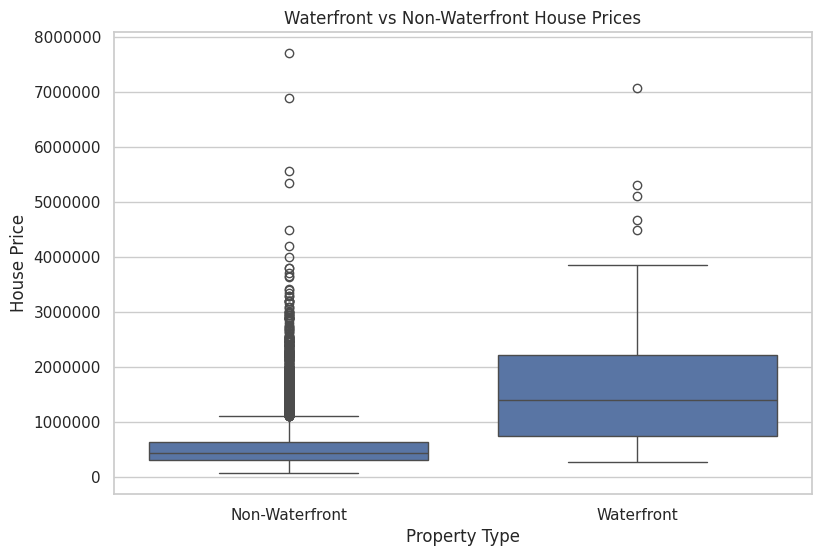

In [13]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="waterfront_label",
    y="price"
)

plt.title("Waterfront vs Non-Waterfront House Prices")
plt.xlabel("Property Type")
plt.ylabel("House Price")
plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.show()

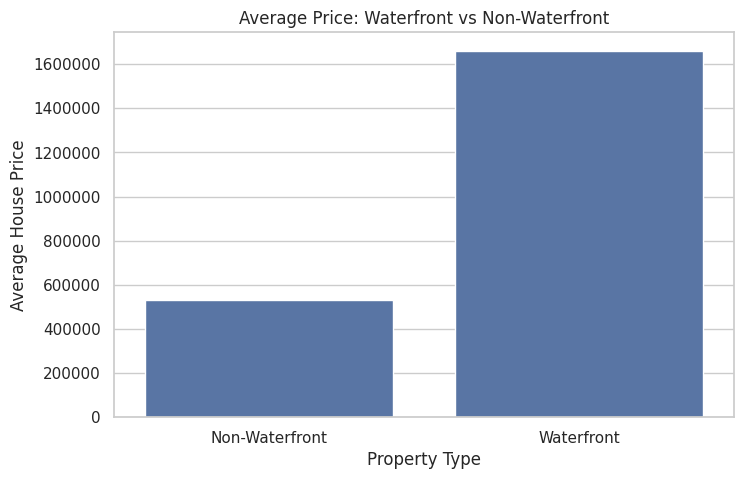

In [14]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=waterfront_summary,
    x="waterfront_label",
    y="mean"
)

plt.title("Average Price: Waterfront vs Non-Waterfront")
plt.xlabel("Property Type")
plt.ylabel("Average House Price")
plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.show()

8. Geographical house-price visualization

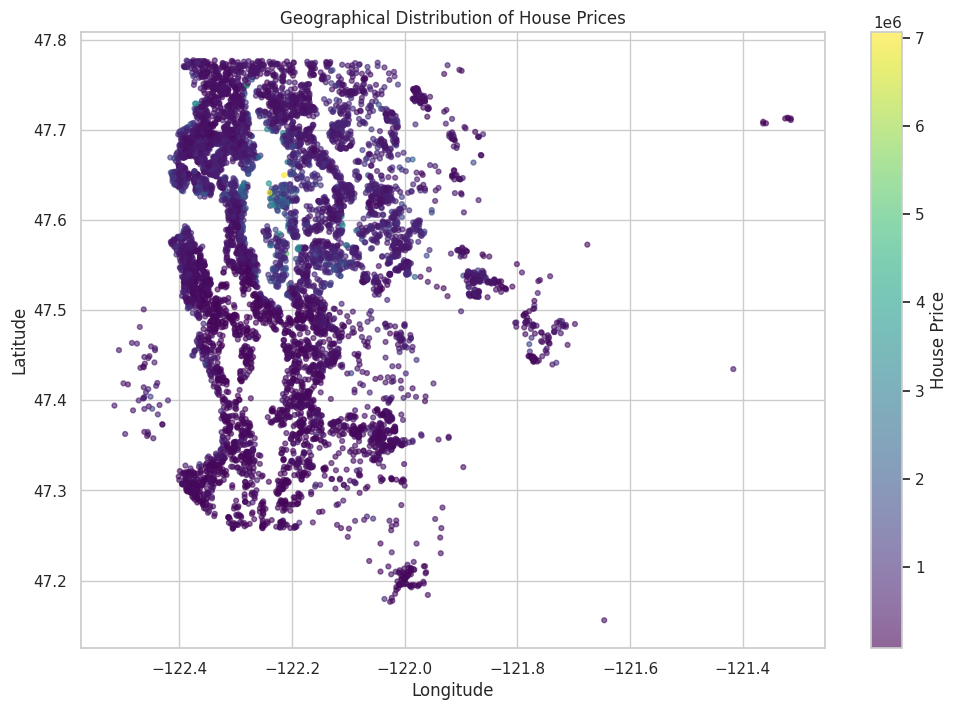

In [15]:
# Sample records to make the plot easier to read
geo_sample = df.sample(
    min(8000, len(df)),
    random_state=42
)

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    geo_sample["long"],
    geo_sample["lat"],
    c=geo_sample["price"],
    cmap="viridis",
    s=12,
    alpha=0.6
)

plt.colorbar(
    scatter,
    label="House Price"
)

plt.title("Geographical Distribution of House Prices")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

9. Identify high-value geographical clusters

In [16]:
# Create geographical grid cells
df["lat_grid"] = df["lat"].round(2)
df["long_grid"] = df["long"].round(2)

location_summary = (
    df.groupby(["lat_grid", "long_grid"])
    .agg(
        property_count=("price", "count"),
        median_price=("price", "median"),
        average_price=("price", "mean"),
        median_price_per_sqft=("price_per_sqft", "median")
    )
    .reset_index()
)

# Keep clusters with at least 10 properties
location_summary = location_summary[
    location_summary["property_count"] >= 10
].copy()

location_summary = location_summary.sort_values(
    "median_price",
    ascending=False
)

print("Top 10 High-Value Geographical Clusters")

display(
    location_summary.head(10).round(2)
)

Top 10 High-Value Geographical Clusters


,lat_grid,long_grid,property_count,median_price,average_price,median_price_per_sqft
1337,47.62,-122.24,13,2100000.0,2229226.92,581.40
1460,47.65,-122.22,10,1898000.0,1954960.00,607.40
1374,47.63,-122.22,17,1749000.0,1872682.35,558.82
1339,47.62,-122.22,26,1720375.0,2124067.31,550.33
1370,47.63,-122.29,25,1715000.0,1663830.00,456.80
1338,47.62,-122.23,11,1650000.0,1839384.55,565.07
1500,47.66,-122.27,18,1575000.0,1641694.44,472.15
1308,47.61,-122.21,10,1507500.0,1689800.00,527.10
1340,47.62,-122.21,26,1465000.0,1586240.38,537.04
1419,47.64,-122.21,18,1429000.0,1545111.11,456.71


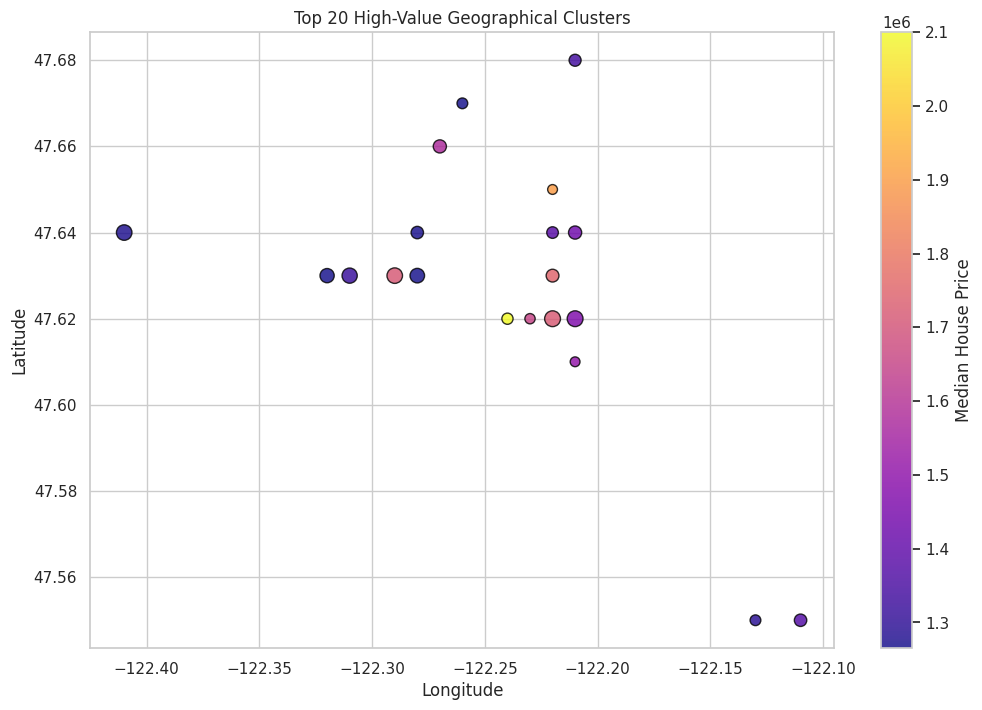

In [17]:
top_clusters = location_summary.head(20)

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    top_clusters["long_grid"],
    top_clusters["lat_grid"],
    c=top_clusters["median_price"],
    s=top_clusters["property_count"] * 5,
    cmap="plasma",
    alpha=0.8,
    edgecolors="black"
)

plt.colorbar(
    scatter,
    label="Median House Price"
)

plt.title("Top 20 High-Value Geographical Clusters")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

10. Identify relatively affordable geographical clusters

In [18]:
affordable_clusters = location_summary.sort_values(
    "median_price",
    ascending=True
).head(20)

print("20 Relatively Affordable Geographical Clusters")

display(
    affordable_clusters.round(2)
)

20 Relatively Affordable Geographical Clusters


,lat_grid,long_grid,property_count,median_price,average_price,median_price_per_sqft
907,47.51,-122.35,10,182500.0,207200.00,164.66
166,47.30,-122.22,21,188200.0,198116.43,142.53
252,47.33,-122.34,24,194975.0,200743.33,176.96
251,47.33,-122.35,15,198500.0,220246.67,154.76
144,47.29,-122.19,11,200000.0,219422.73,147.06
119,47.28,-122.25,10,202975.0,209834.00,127.81
162,47.30,-122.28,10,207500.0,225228.00,115.06
874,47.50,-122.32,15,209000.0,217833.33,169.78
878,47.50,-122.27,11,210000.0,213035.27,167.86
565,47.42,-122.32,28,211250.0,222797.32,166.59


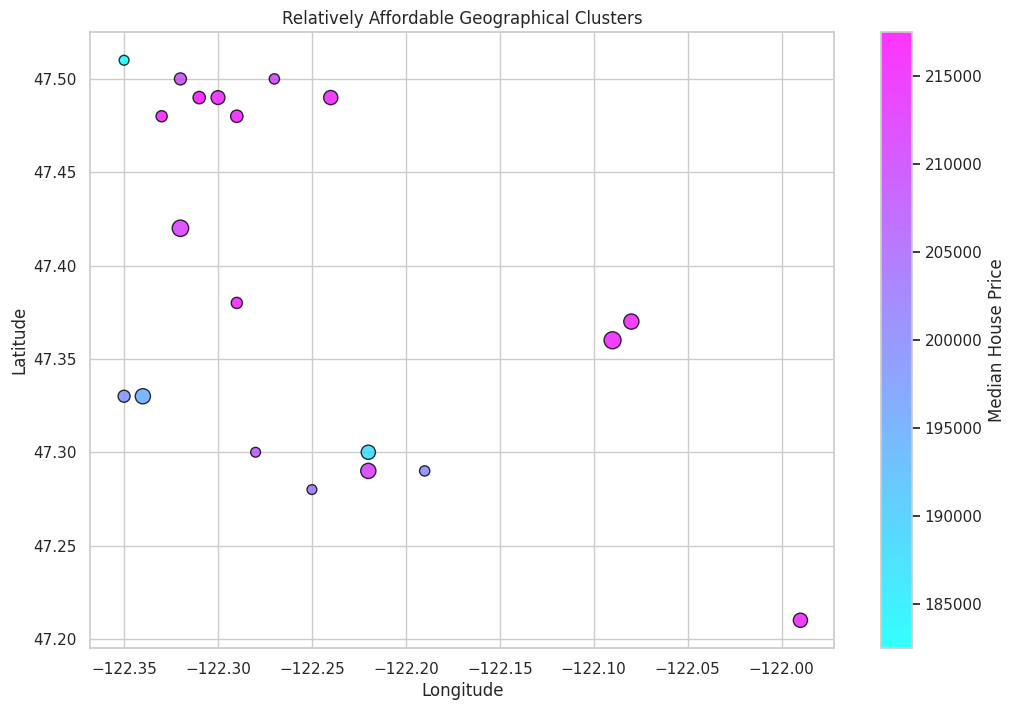

In [19]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    affordable_clusters["long_grid"],
    affordable_clusters["lat_grid"],
    c=affordable_clusters["median_price"],
    s=affordable_clusters["property_count"] * 5,
    cmap="cool",
    alpha=0.8,
    edgecolors="black"
)

plt.colorbar(
    scatter,
    label="Median House Price"
)

plt.title("Relatively Affordable Geographical Clusters")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

11. Analyze price per square foot

In [20]:
price_per_sqft_summary = (
    df.groupby("grade")["price_per_sqft"]
    .agg(
        ["count", "mean", "median", "min", "max"]
    )
    .round(2)
    .reset_index()
)

display(price_per_sqft_summary)

,grade,count,mean,median,min,max
0,1,1,489.66,489.66,489.66,489.66
1,3,3,360.82,466.67,111.94,503.85
2,4,29,362.38,302.08,98.96,792.68
3,5,242,278.93,225.30,89.29,787.04
4,6,2038,270.99,241.05,87.65,792.11
5,7,8981,251.90,228.40,87.59,810.14
6,8,6068,258.09,247.09,88.03,785.34
7,9,2615,275.77,254.75,87.71,766.28
8,10,1134,307.59,272.26,96.72,776.89
9,11,399,342.25,295.06,106.95,800.00


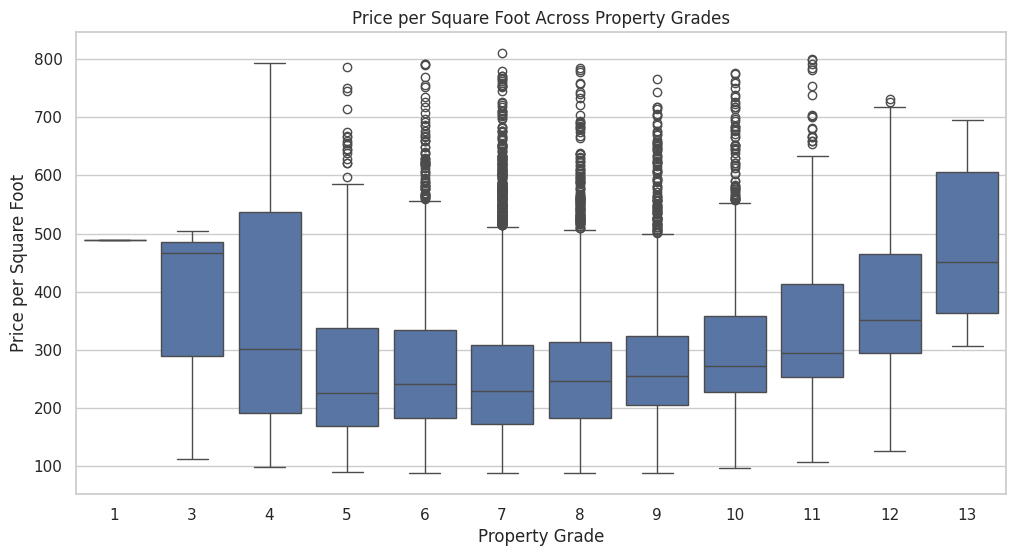

In [21]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="grade",
    y="price_per_sqft"
)

plt.title("Price per Square Foot Across Property Grades")
plt.xlabel("Property Grade")
plt.ylabel("Price per Square Foot")

plt.show()

12. Analyze sale-year trends

,sale_year,count,mean,median
0,2014,14633,539181.43,450000.0
1,2015,6980,541988.99,450500.0


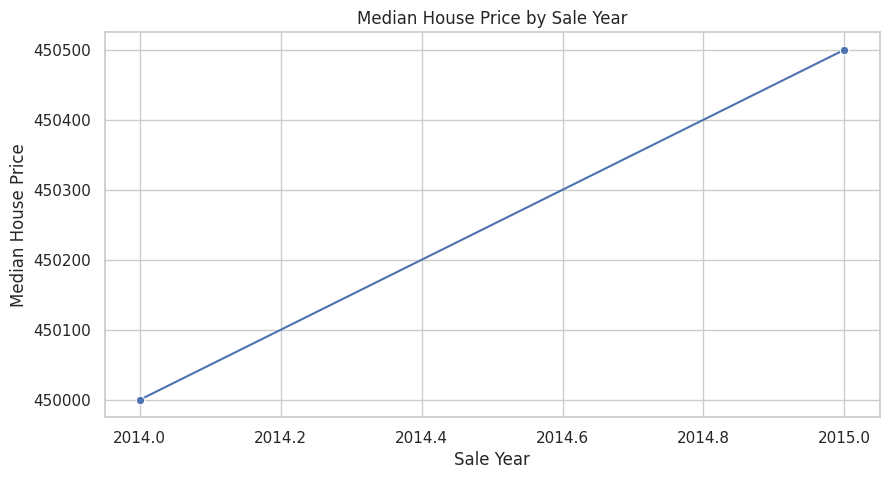

In [22]:
if "sale_year" in df.columns:

    yearly_summary = (
        df.groupby("sale_year")["price"]
        .agg(["count", "mean", "median"])
        .reset_index()
        .round(2)
    )

    display(yearly_summary)

    plt.figure(figsize=(10, 5))

    sns.lineplot(
        data=yearly_summary,
        x="sale_year",
        y="median",
        marker="o"
    )

    plt.title("Median House Price by Sale Year")
    plt.xlabel("Sale Year")
    plt.ylabel("Median House Price")
    plt.ticklabel_format(
        style="plain",
        axis="y"
    )

    plt.show()

else:
    print("sale_year column is not available.")

13. Generate real-estate investment insights

In [23]:
# Overall market statistics
overall_summary = pd.DataFrame({
    "Metric": [
        "Total Properties",
        "Average House Price",
        "Median House Price",
        "Average Living Area",
        "Average Price per Square Foot",
        "Highest House Price",
        "Lowest House Price"
    ],
    "Value": [
        len(df),
        df["price"].mean(),
        df["price"].median(),
        df["sqft_living"].mean(),
        df["price_per_sqft"].mean(),
        df["price"].max(),
        df["price"].min()
    ]
})

display(overall_summary.round(2))

,Metric,Value
0,Total Properties,21613.00
1,Average House Price,540088.14
2,Median House Price,450000.00
3,Average Living Area,2079.90
4,Average Price per Square Foot,264.16
5,Highest House Price,7700000.00
6,Lowest House Price,75000.00


In [24]:
high_value_report = location_summary.head(10).copy()
high_value_report["cluster_type"] = "High-Value"

affordable_report = (
    location_summary.sort_values(
        "median_price",
        ascending=True
    ).head(10).copy()
)

affordable_report["cluster_type"] = "Relatively Affordable"

investment_report = pd.concat(
    [high_value_report, affordable_report],
    ignore_index=True
)

investment_report = investment_report[
    [
        "cluster_type",
        "lat_grid",
        "long_grid",
        "property_count",
        "median_price",
        "average_price",
        "median_price_per_sqft"
    ]
]

display(investment_report.round(2))

,cluster_type,lat_grid,long_grid,property_count,median_price,average_price,median_price_per_sqft
0,High-Value,47.62,-122.24,13,2100000.0,2229226.92,581.40
1,High-Value,47.65,-122.22,10,1898000.0,1954960.00,607.40
2,High-Value,47.63,-122.22,17,1749000.0,1872682.35,558.82
3,High-Value,47.62,-122.22,26,1720375.0,2124067.31,550.33
4,High-Value,47.63,-122.29,25,1715000.0,1663830.00,456.80
5,High-Value,47.62,-122.23,11,1650000.0,1839384.55,565.07
6,High-Value,47.66,-122.27,18,1575000.0,1641694.44,472.15
7,High-Value,47.61,-122.21,10,1507500.0,1689800.00,527.10
8,High-Value,47.62,-122.21,26,1465000.0,1586240.38,537.04
9,High-Value,47.64,-122.21,18,1429000.0,1545111.11,456.71


In [25]:
highest_grade = grade_summary.loc[
    grade_summary["mean"].idxmax()
]

highest_waterfront = waterfront_summary.loc[
    waterfront_summary["mean"].idxmax()
]

correlation = df[
    ["sqft_living", "price"]
].corr().iloc[0, 1]

print("REAL-ESTATE MARKET INSIGHTS REPORT")
print("----------------------------------")

print(
    f"1. The dataset contains {len(df)} valid property records."
)

print(
    f"2. The median house price is "
    f"{df['price'].median():,.2f}."
)

print(
    f"3. The correlation between living area and price is "
    f"{correlation:.3f}."
)

print(
    f"4. Grade {highest_grade['grade']} has the highest "
    f"average price among the available property grades."
)

print(
    f"5. {highest_waterfront['waterfront_label']} properties "
    f"have the highest average price between the two "
    f"waterfront groups."
)

if not location_summary.empty:
    top_location = location_summary.iloc[0]

    print(
        f"6. The highest-median-price grid is approximately "
        f"latitude {top_location['lat_grid']} and "
        f"longitude {top_location['long_grid']}."
    )

print(
    "7. Review the high-value and relatively affordable "
    "cluster tables for geographical comparisons."
)

print(
    "8. These findings describe patterns in the dataset "
    "and should not be treated as predictions of future returns."
)

REAL-ESTATE MARKET INSIGHTS REPORT
----------------------------------
1. The dataset contains 21613 valid property records.
2. The median house price is 450,000.00.
3. The correlation between living area and price is 0.702.
4. Grade 13.0 has the highest average price among the available property grades.
5. Waterfront properties have the highest average price between the two waterfront groups.
6. The highest-median-price grid is approximately latitude 47.62 and longitude -122.24.
7. Review the high-value and relatively affordable cluster tables for geographical comparisons.
8. These findings describe patterns in the dataset and should not be treated as predictions of future returns.


14. Export all reports

In [26]:
os.makedirs("week10_reports", exist_ok=True)

# Save overall market summary
overall_summary.to_csv(
    "week10_reports/overall_market_summary.csv",
    index=False
)

# Save grade analysis
grade_summary.to_csv(
    "week10_reports/grade_price_summary.csv",
    index=False
)

# Save waterfront analysis
waterfront_summary.to_csv(
    "week10_reports/waterfront_price_summary.csv",
    index=False
)

# Save geographical cluster analysis
location_summary.to_csv(
    "week10_reports/geographical_cluster_summary.csv",
    index=False
)

# Save price per square foot analysis
price_per_sqft_summary.to_csv(
    "week10_reports/price_per_sqft_summary.csv",
    index=False
)

# Save investment insights
investment_report.to_csv(
    "week10_reports/real_estate_investment_insights.csv",
    index=False
)

# Save yearly analysis if available
if "sale_year" in df.columns:
    yearly_summary.to_csv(
        "week10_reports/yearly_price_summary.csv",
        index=False
    )

# Save the analysis dataset
df.to_csv(
    "week10_reports/house_sales_week10_analysis.csv",
    index=False
)

print("All Week 10 reports saved successfully.")

All Week 10 reports saved successfully.
